## Mobile App Success Analysis

In [4]:
# data loading
import pandas as pd

df = pd.read_csv("mobileApp_dataset.csv")

print(df.shape)
df.head()

(1939, 18)


,app_name,developer,category,rating,rating_count,price_usd,is_free,size_mb,language_count,release_year,supports_ipad,age_rating,description_length,chart_rank,chart_type,category_popularity,update_frequency,app_id
0,Jigsaw Puzzles - Puzzle Games,Easybrain Ltd,Games,4.74,1086500.0,0.0,1,216.7,17,2018,1,12+,231,NaN,NaN,454,8,1324604053
1,Brain Test: Tricky Puzzles,UNICO STUDIO,Games,4.79,1414966.0,0.0,1,273.9,19,2019,1,4+,397,NaN,NaN,454,7,1486214495
2,Flow Free,Big Duck Games LLC,Games,4.78,392209.0,0.0,1,66.4,11,2012,1,4+,228,NaN,NaN,454,14,526641427
3,Block Blast！,Hungry Studio,Games,4.88,2447566.0,0.0,1,171.7,49,2022,1,12+,368,NaN,NaN,454,4,1617391485
4,BlockPuz - Block Puzzles Games,LI SAIHUA,Games,4.90,194527.0,0.0,1,314.7,14,2021,1,4+,88,NaN,NaN,454,5,1547762178


In [5]:
# Adding Styles

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt

# global style constants
BG    = "#0f1117"
CARD  = "#1a1d27"
HIT   = "#43e97b"
MISS  = "#ff6584"
ACC1  = "#6c63ff"
ACC2  = "#00d4ff"
GRAY  = "#8892a4"
WHITE = "#e8ecf0"

plt.rcParams.update({
    'figure.facecolor': BG,
    'axes.facecolor': CARD,
    'axes.edgecolor': '#2a2d3a',
    'axes.labelcolor': GRAY,
    'xtick.color': GRAY,
    'ytick.color': GRAY,
    'text.color': WHITE,
    'grid.color': '#2a2d3a',
    'grid.linestyle': '--',
    'grid.linewidth': 0.8,
})

def sa(ax, title="", xlabel="", ylabel=""):
    ax.set_facecolor(CARD)
    for sp in ax.spines.values():
        sp.set_edgecolor('#2a2d3a')
    ax.tick_params(colors=GRAY, labelsize=9)
    if title:  ax.set_title(title, color=WHITE, fontsize=13, fontweight='bold')
    if xlabel: ax.set_xlabel(xlabel, color=GRAY)
    if ylabel: ax.set_ylabel(ylabel, color=GRAY)

print("Style ready.")

Style ready.


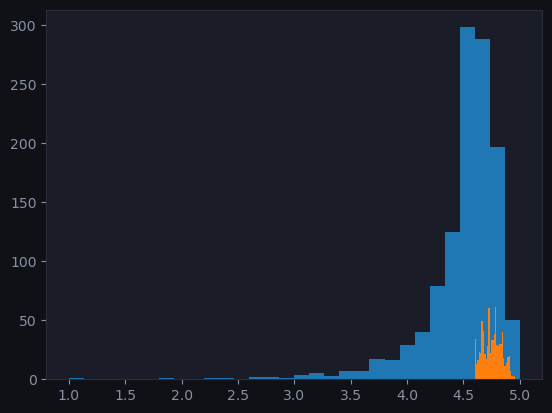

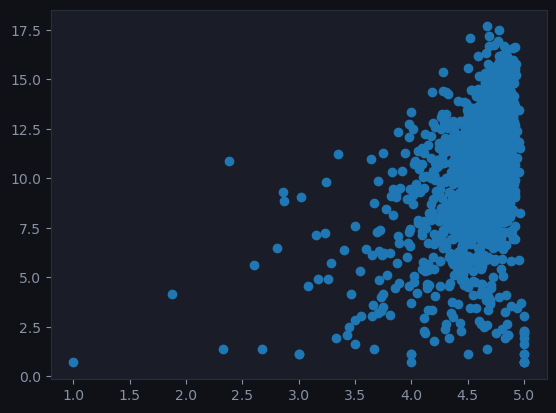

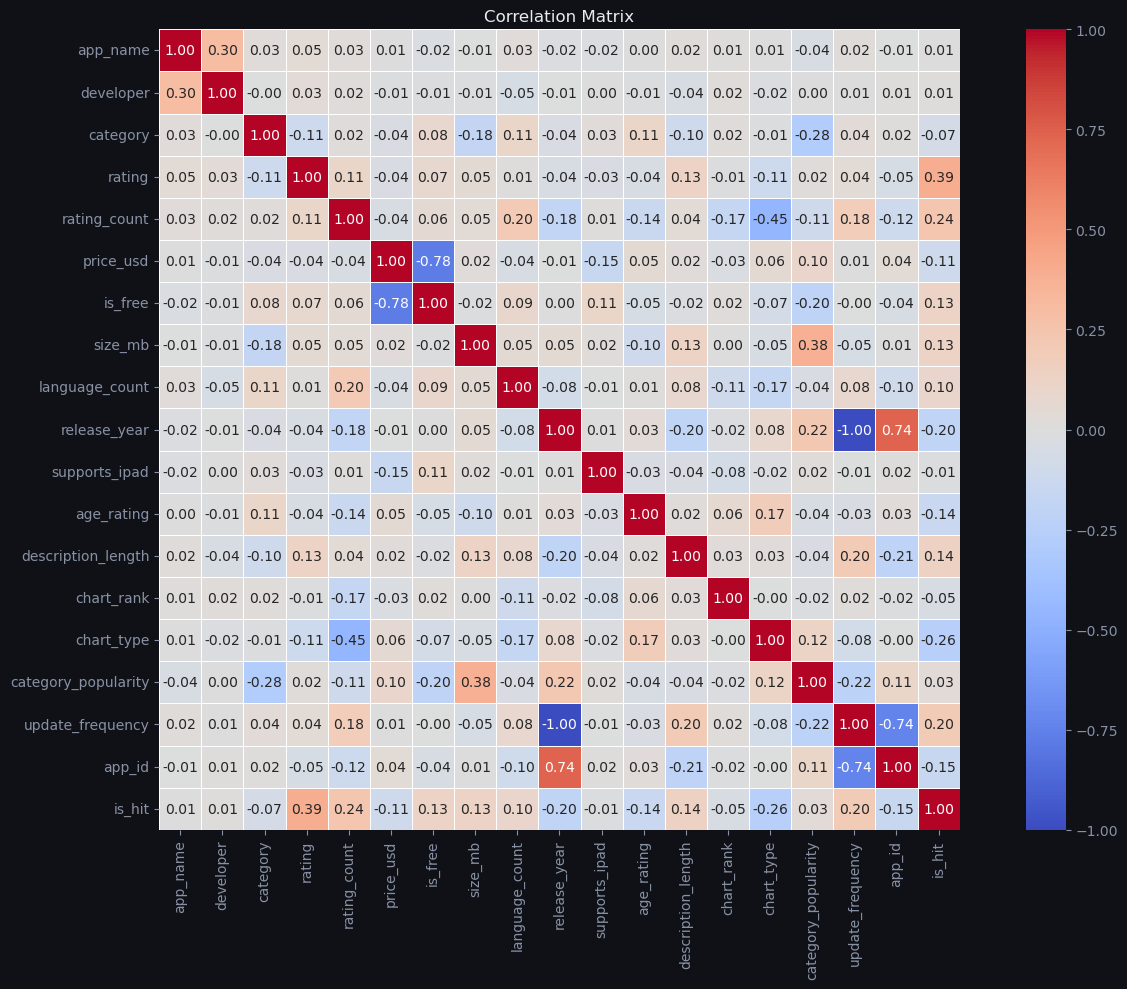


Processed dataset saved as: processed_mobile_apps.csv

Dataset Shape: (1939, 19)


In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Create copy
df_enc = df.copy()

# =========================
# Missing Value Handling
# =========================

# Numeric columns
df_enc['rating'] = df_enc['rating'].fillna(df_enc['rating'].median())
df_enc['rating_count'] = df_enc['rating_count'].fillna(df_enc['rating_count'].median())
df_enc['chart_rank'] = df_enc['chart_rank'].fillna(df_enc['chart_rank'].median())

# Categorical columns
df_enc['chart_type'] = df_enc['chart_type'].fillna(
    df_enc['chart_type'].mode()[0]
)

# Label Creation(Label y value)

import numpy as np

RATING_THRESH = 4.6
COUNT_THRESH = df_enc['rating_count'].median()

df_enc['is_hit'] = (
    (df_enc['rating'] >= RATING_THRESH) &
    (df_enc['rating_count'] >= COUNT_THRESH)
).astype(int)

df_enc['is_hit'].value_counts()


# Distribution Plot

import seaborn as sns
import matplotlib.patches as mpatches

fig, ax = plt.subplots()
ax.hist(df_enc[df_enc['is_hit']==0]['rating'], bins=30) # Blue
ax.hist(df_enc[df_enc['is_hit']==1]['rating'], bins=30) # Yellow
plt.show()

# Scatter Plot

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.scatter(df_enc['rating'], np.log1p(df_enc['rating_count']))
plt.show()

# =========================
# Label Encoding
# =========================

le_dev = LabelEncoder()
le_cat = LabelEncoder()
le_age = LabelEncoder()
le_chart = LabelEncoder()
le_app = LabelEncoder()

df_enc['developer'] = le_dev.fit_transform(
    df_enc['developer'].astype(str)
)

df_enc['category'] = le_cat.fit_transform(
    df_enc['category'].astype(str)
)

df_enc['age_rating'] = le_age.fit_transform(
    df_enc['age_rating'].astype(str)
)

df_enc['chart_type'] = le_chart.fit_transform(
    df_enc['chart_type'].astype(str)
)

df_enc['app_name'] = le_app.fit_transform(
    df_enc['app_name'].astype(str)
)

# =========================
# Correlation Matrix
# =========================

corr = df_enc.select_dtypes(include=np.number).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# =========================
# Save Processed Dataset
# =========================

output_filename = "processed_mobile_apps.csv"
df_enc.to_csv(output_filename, index=False)

print(f"\nProcessed dataset saved as: {output_filename}")

print("\nDataset Shape:", df_enc.shape)

### Correlation Check with Y

In [7]:
import pandas as pd

# Load your dataset
df = pd.read_csv('processed_mobile_apps.csv')

# Define your target variable y
y = df['is_hit']

# Define X: Drop the target and any non-numeric columns
# Adjust 'is_hit' to include other columns you wish to exclude (e.g., 'app_name')
X = df.drop(columns=['is_hit']) 

# Now calculate correlation with y
correlation = X.corrwith(y)

# 1. Print sorted by raw values (High to Low)
print("--- Correlation (Sorted by Value) ---")
print(correlation.sort_values(ascending=False))
print("\n")

# 2. Print sorted by magnitude (Absolute Value)
magnitude_sorted = correlation.reindex(correlation.abs().sort_values(ascending=False).index)

print("--- Correlation (Sorted by Magnitude) ---")
print(magnitude_sorted)

--- Correlation (Sorted by Value) ---
rating                 0.391567
rating_count           0.240800
update_frequency       0.202805
description_length     0.142978
size_mb                0.130990
is_free                0.128742
language_count         0.099280
category_popularity    0.033448
developer              0.008205
app_name               0.007001
supports_ipad         -0.012022
chart_rank            -0.046518
category              -0.067645
price_usd             -0.107181
age_rating            -0.141966
app_id                -0.151786
release_year          -0.202805
chart_type            -0.255617
dtype: float64


--- Correlation (Sorted by Magnitude) ---
rating                 0.391567
chart_type            -0.255617
rating_count           0.240800
update_frequency       0.202805
release_year          -0.202805
app_id                -0.151786
description_length     0.142978
age_rating            -0.141966
size_mb                0.130990
is_free                0.128742
price_u

### Feature Selection

In [8]:
import pandas as pd

# Load the dataset
df = pd.read_csv('processed_mobile_apps.csv')

# Columns to remove
cols_to_remove = ['rating', 'rating_count', 'app_name', 'app_id', 'is_free', 'release_year', 'chart_rank', 'chart_type','supports_ipad','category_popularity','developer']

# Drop the columns
df_selected = df.drop(columns=cols_to_remove)

# Save to CSV
df_selected.to_csv('featureSelected.csv', index=False)

# Optional: Print the remaining columns to verify
print("Remaining columns:", df_selected.columns.tolist())

Remaining columns: ['category', 'price_usd', 'size_mb', 'language_count', 'age_rating', 'description_length', 'update_frequency', 'is_hit']


### Feature Engineering

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load your dataset
df = pd.read_csv('featureSelected.csv')

# 1. Apply Log Transformation to highly skewed features
# np.log1p calculates log(1 + x)
skewed_features = ['size_mb', 'language_count']
for feature in skewed_features:
    df[feature] = np.log1p(df[feature])

# 2. Apply Standard Scaling to symmetric features
symmetric_features = ['description_length', 'update_frequency']
scaler = StandardScaler()
df[symmetric_features] = scaler.fit_transform(df[symmetric_features])

# Save the transformed dataset
df.to_csv('featureSelected_transformed.csv', index=False)

print("Transformations complete. Saved to 'featureSelected_transformed.csv'.")

Transformations complete. Saved to 'featureSelected_transformed.csv'.


### Split Data

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the transformed dataset
df = pd.read_csv('featureSelected_transformed.csv')

# 2. Separate features (X) and target (y)
X = df.drop(columns=['is_hit'])
y = df['is_hit']

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Save the splits to CSV files
X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

# Verify the shapes
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print("Datasets saved as CSV files.")

Training set shape: (1551, 7)
Testing set shape: (388, 7)
Datasets saved as CSV files.


### Model Training & Evaluation

1. Random Forest

--- Random Forest Report ---
              precision    recall  f1-score   support

           0       0.77      0.82      0.79       242
           1       0.66      0.58      0.62       146

    accuracy                           0.73       388
   macro avg       0.71      0.70      0.71       388
weighted avg       0.73      0.73      0.73       388



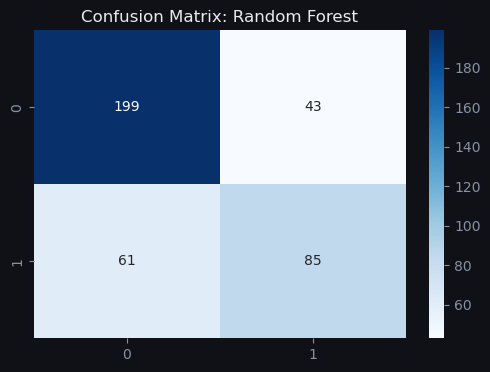

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Load the training and testing datasets
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv').values.ravel()
y_test = pd.read_csv('y_test.csv').values.ravel()

# 2. Train the Random Forest Model
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

# 3. Print the Metrics Report
print("--- Random Forest Report ---")
print(classification_report(y_test, y_pred))

# 4. Create and Save the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Random Forest')
plt.savefig('rf_confusion_matrix.png')
plt.show()

2. XGBoost

In [12]:
!pip install xgboost

--- XGBoost Report ---
              precision    recall  f1-score   support

           0       0.74      0.80      0.77       242
           1       0.62      0.53      0.57       146

    accuracy                           0.70       388
   macro avg       0.68      0.67      0.67       388
weighted avg       0.69      0.70      0.70       388



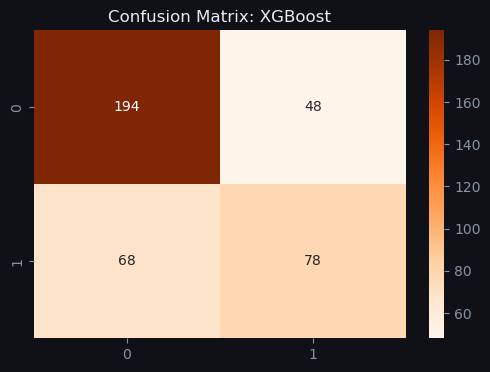

In [15]:
from xgboost import XGBClassifier

# Train
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)

# Metrics
print("--- XGBoost Report ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title('Confusion Matrix: XGBoost')
plt.savefig('xgb_confusion_matrix.png')
plt.show()

### Model Comparison

In [16]:
import pandas as pd

# 1. Define the data
# Metrics extracted from your provided Classification Reports (using macro averages)
data = {
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [0.73, 0.70],
    'Precision': [0.71, 0.68],
    'Recall': [0.70, 0.67],
    'F1-Score': [0.71, 0.67]
}

df_results = pd.DataFrame(data)

# 2. Apply styling and format to 2 decimal places
styled_table = df_results.style.format("{:.2f}", subset=['Accuracy', 'Precision', 'Recall', 'F1-Score']) \
                               .background_gradient(cmap='Blues', subset=['Accuracy', 'Precision', 'Recall', 'F1-Score']) \
                               .set_caption("Model Performance Comparison") \
                               .set_properties(**{'text-align': 'center'})

# 3. Display the table
styled_table

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.73,0.71,0.70,0.71
1,XGBoost,0.70,0.68,0.67,0.67


### 

              Feature  Importance
2             size_mb    0.285724
5  description_length    0.209867
6    update_frequency    0.147759
3      language_count    0.143679
0            category    0.129505
4          age_rating    0.061294
1           price_usd    0.022171


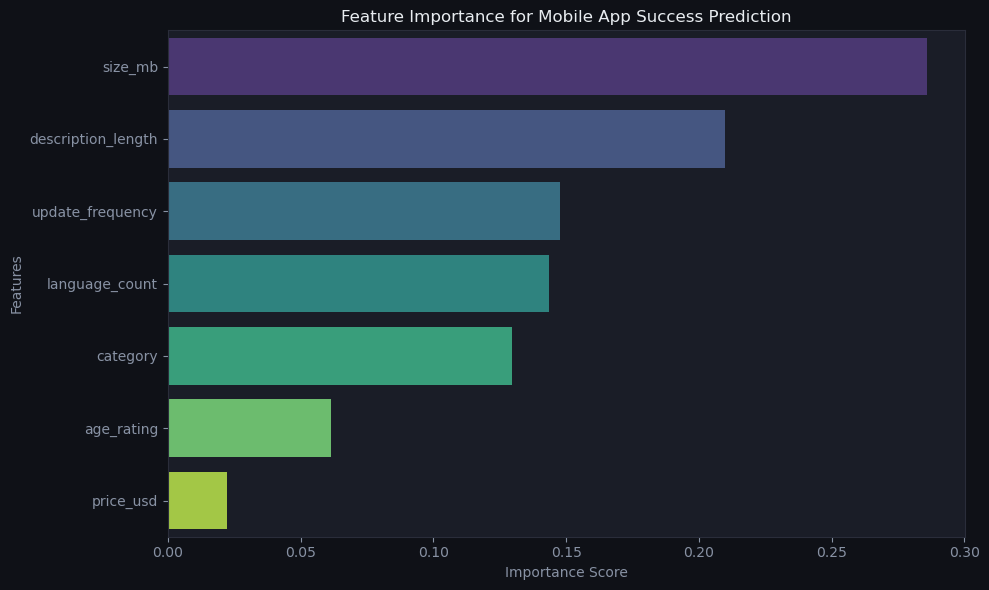

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance scores from the trained Random Forest model
importances = rf.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display importance values
print(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Feature Importance for Mobile App Success Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()